# Week 4: final results, and where the best model is still wrong

Same steps as `src/05_week4.py`, with explanations. Shared helpers live in `src/cmapss.py`.

**Goal this week:** one table with every final number, and an honest look at the mistakes that the single overall score hides.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')   # let the notebook find our helper file in src/
# numpy 2.0 on Apple chips prints false 'overflow in matmul' alarms (verified harmless in Week 2)
warnings.filterwarnings('ignore', message='.*encountered in matmul')
%matplotlib inline
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from cmapss import (RUL_CAP, load_train, clip_rul, feature_columns, load_test_last_rows,
                    rmse, stage_of_life, plot_error_by_stage)

train = load_train()               # labels as they really are (raw)
train_c = clip_rul(train)          # labels capped at 125
features = feature_columns(train)  # the 17 clue columns
test_last = load_test_last_rows()  # last flight of each test engine + true RUL
truth = test_last.RUL

## Step 1: Every final number, rebuilt from scratch

The four main models are trained again here, so the results table can be checked by running one cell. *Too high* counts the engines where the model promised more life than the engine really had, which is the unsafe direction.

In [2]:
def new_gb():
    return GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=0)

LIN, GB = f'Linear regression, clipped at {RUL_CAP}', f'Gradient boosting, clipped at {RUL_CAP}'
preds = {
    'Mean baseline': np.full(len(test_last), train.RUL.mean()),
    'Linear regression, raw labels': LinearRegression().fit(train[features], train.RUL).predict(test_last[features]),
    LIN: LinearRegression().fit(train_c[features], train_c.RUL).predict(test_last[features]),
    GB: new_gb().fit(train_c[features], train_c.RUL).predict(test_last[features]),
}
pd.DataFrame([{'model': n, 'test RMSE': rmse(truth, p), 'too high (of 100)': int((p > truth).sum()),
               'worst miss': float(np.abs(p - truth).max())} for n, p in preds.items()]).round(2)

,model,test RMSE,too high (of 100),worst miss
0,Mean baseline,52.62,71,100.81
1,"Linear regression, raw labels",32.04,85,78.75
2,"Linear regression, clipped at 125",21.90,58,60.28
3,"Gradient boosting, clipped at 125",18.36,53,54.56


## Step 2: Where is the best model wrong?

One average hides where the mistakes are. Here the 100 test engines are sorted into three groups by how many flights they **truly** have left, and each group is scored on its own.

In [3]:
best = preds[GB]
stage = stage_of_life(truth)
rows = []
for g in stage.cat.categories:
    m = (stage == g).to_numpy()
    rows.append({'group (true flights left)': g, 'engines': int(m.sum()),
                 'RMSE': rmse(truth[m], best[m]), 'average error': (best[m] - truth[m]).mean()})
pd.DataFrame(rows).round(1)

,group (true flights left),engines,RMSE,average error
0,close to failure (0-30),25,18.3,8.5
1,wearing (31-125),64,17.9,5.0
2,healthy (over 125),11,21.1,-19.9


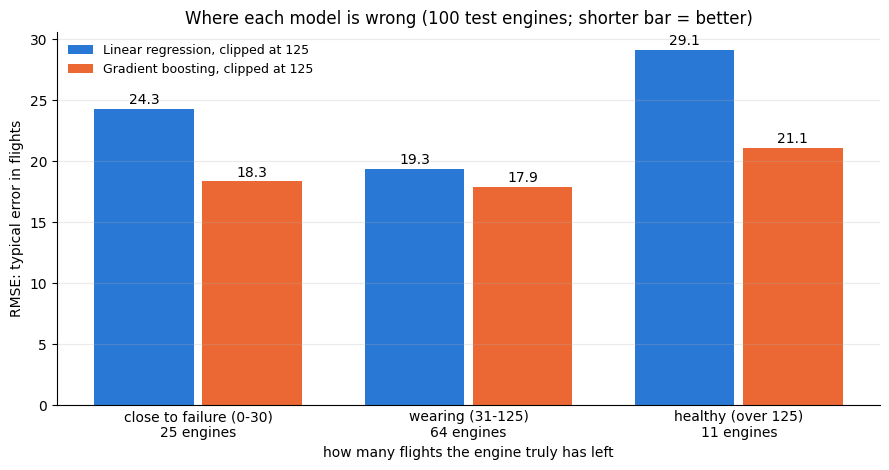

In [4]:
fig = plot_error_by_stage(truth, {LIN: preds[LIN], GB: best})

**Reading the chart:** gradient boosting (orange) beats linear regression (blue) in every group. But its error is about 18 flights even for engines close to failure, where a miss matters most. The next cell looks inside that group.

In [5]:
near = (truth <= 30).to_numpy()
miss = best[near] - truth[near]
print(f'middle (median) miss: {np.median(np.abs(miss)):.1f} flights')
print(f'within 10 flights of the truth: {(np.abs(miss) <= 10).sum()} of {near.sum()} engines')
print(f'too HIGH by more than 20 flights: {(miss > 20).sum()} engines')
(test_last[near].assign(predicted=best[near], miss=miss).nlargest(5, 'miss')
 [['unit', 'cycle', 'RUL', 'predicted', 'miss']].round(0))

middle (median) miss: 4.1 flights
within 10 flights of the truth: 18 of 25 engines
too HIGH by more than 20 flights: 5 engines


,unit,cycle,RUL,predicted,miss
40,41,123,18,72.0,54.0
36,37,121,21,65.0,44.0
17,18,133,28,70.0,42.0
63,64,168,28,55.0,27.0
60,61,159,21,44.0,23.0


**The honest finding:** for most engines near failure the model is close (the middle miss is about 4 flights). But for 5 of the 25 it is too high by 23 to 54 flights. Engine 41 has 18 flights left and the model says 72. A few large misses, all in the unsafe direction, are what push this group's RMSE to 18.

All five had flown fewer than 170 flights, so they are engines that wore out early. Why the model misses them is **not yet explained**.

## Step 3: How much error does clipping build in?

A model trained on labels capped at 125 can never answer much more than 125. Imagine a *perfect* clipped model: exactly right below 125, and saying 125 for anything above. Its score is the best any clipped model could get on this test set.

In [6]:
healthy = (truth > RUL_CAP).to_numpy()
print(f'highest prediction the best model ever makes: {best.max():.1f}')
print(f'score of a perfect clipped model: {rmse(truth, np.minimum(truth, RUL_CAP)):.2f}')
print(f'best model on the {(~healthy).sum()} engines at or below {RUL_CAP}: {rmse(truth[~healthy], best[~healthy]):.2f}')

highest prediction the best model ever makes: 122.7
score of a perfect clipped model: 3.74
best model on the 89 engines at or below 125: 18.00


Clipping costs very little: a perfect clipped model would still score about 3.7. And leaving out the 11 healthy engines barely changes our score (18.4 to 18.0). So the cap is **not** what holds the model back. The remaining error comes from engines in the range where the model is supposed to work.

**Final result: gradient boosting with labels clipped at 125, test RMSE 18.36.**